# 01. Exploratory Data Analysis & Sensor Modalities

This notebook analyzes the three ocular datasets used in NoNooze:
1. **MRL Eye Dataset** (Infrared / 84k images / 37 subjects)
2. **CEW (Closed Eyes in the Wild)** (RGB / 2.4k wild images)
3. **Local RGB Device Crops** (Captured by `src/wake/dev/collector.ts`)

We investigate the domain gap between Active Infrared (IR) and Mobile RGB Front Cameras.

In [1]:
import sys, os
from pathlib import Path
_root = Path(os.path.abspath('.')).parent if Path(os.path.abspath('.')).name == 'ml' else Path(os.path.abspath('.'))
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
import sys
from pathlib import Path
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from ml.src.dataset import load_dataset_from_directory, split_by_subject

print("EDA libraries loaded successfully.")

EDA libraries loaded successfully.


In [2]:
# Load samples from dataset directory
data_dir = Path("ml/mock_data") # Or path to full downloaded MRL / CEW / phone dataset
samples = load_dataset_from_directory(data_dir)
print(f"Total loaded ocular samples: {len(samples)}")

# Breakdown by domain
domains = {}
for s in samples:
    domains[s.domain] = domains.get(s.domain, 0) + 1

print("Domain breakdown:", domains)

Total loaded ocular samples: 0
Domain breakdown: {}


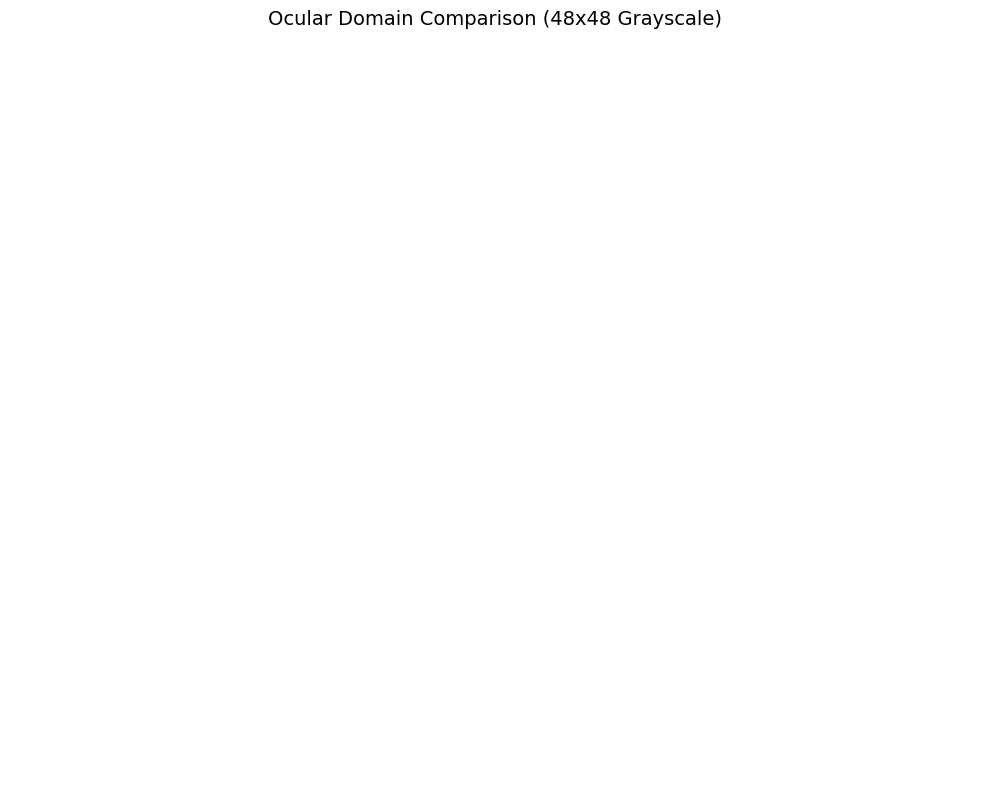

In [3]:
# Visualize sample grids from each domain
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
plt.suptitle("Ocular Domain Comparison (48x48 Grayscale)", fontsize=14)

sample_domains = ['mrl_ir', 'cew_rgb', 'phone_rgb']
for row, domain in enumerate(sample_domains):
    domain_samples = [s for s in samples if s.domain == domain][:4]
    for col in range(4):
        ax = axes[row, col]
        if col < len(domain_samples):
            s = domain_samples[col]
            img = Image.open(s.path).convert("L")
            ax.imshow(img, cmap='gray')
            ax.set_title(f"{s.domain}\n{'Open' if s.label == 1 else 'Closed'}", fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.show()

### Domain Gap Observations:
1. **MRL (IR)**: High contrast pupil/iris reflections under active 850nm IR illumination; skin tones are flat; shadows are absent.
2. **CEW (RGB)**: Subject to ambient sunlight, soft indoor lamps, skin tone heterogeneity, and facial micro-expressions.
3. **Phone (RGB)**: Low angle perspective (looking up from bed), high morning backlight or extreme dark bedroom illumination.

**Mitigation**: Robust augmentations (contrast/CLAHE, gamma/brightness shifts, low-light simulation) are required during training.